	计算指标、绘图和检查失败案例

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

result_dir = Path("reports/morgan_random_forest")

random_predictions = pd.read_csv(
    result_dir / "random_test_predictions.csv",
    index_col="source_row_index",
)
additive_predictions = pd.read_csv(
    result_dir / "additive_test_predictions.csv",
    index_col="source_row_index",
)

evaluation_rows = []

for split_name, table in [
    ("Random split", random_predictions),
    ("Held-out additive", additive_predictions),
]:
    observed = table["Output"]
    predicted = table["predicted_yield"]

    evaluation_rows.append({
        "Split": split_name,
        "Test records": len(table),
        "MAE": mean_absolute_error(observed, predicted),
        "RMSE": np.sqrt(mean_squared_error(observed, predicted)),
        "R2": r2_score(observed, predicted),
    })

evaluation_summary = pd.DataFrame(evaluation_rows)
display(evaluation_summary.round(3))

,Split,Test records,MAE,RMSE,R2
0,Random split,1187,4.689,7.141,0.933
1,Held-out additive,180,8.398,12.130,0.811


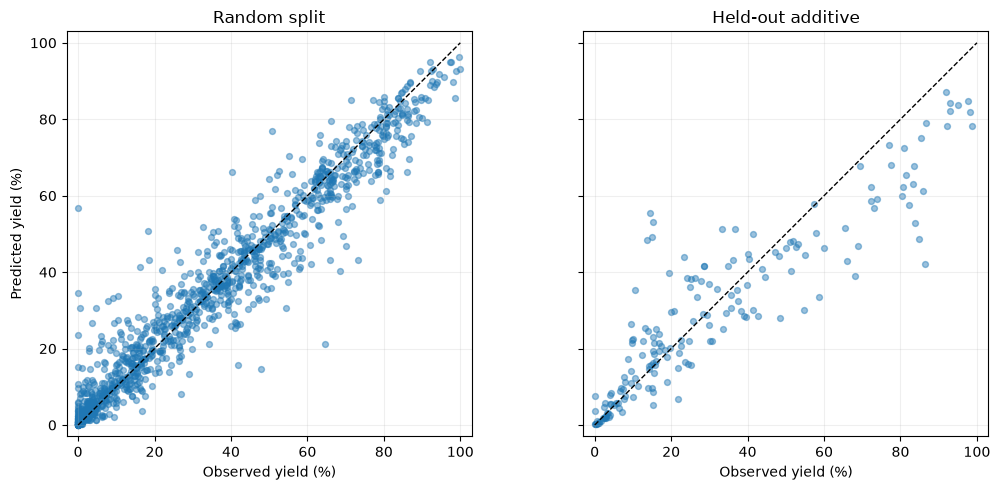

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2, figsize=(11, 5), sharex=True, sharey=True
)

for ax, title, table in [
    (axes[0], "Random split", random_predictions),
    (axes[1], "Held-out additive", additive_predictions),
]:
    ax.scatter(
        table["Output"],
        table["predicted_yield"],
        s=18,
        alpha=0.45,
    )
    ax.plot([0, 100], [0, 100], "--", color="black", linewidth=1)

    ax.set(
        title=title,
        xlabel="Observed yield (%)",
        xlim=(-3, 103),
        ylim=(-3, 103),
    )
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Predicted yield (%)")

fig.tight_layout()
plt.show()

Random split mean residual: 0.00 percentage points
Random split largest absolute error: 56.77
Held-out additive mean residual: 1.64 percentage points
Held-out additive largest absolute error: 44.19


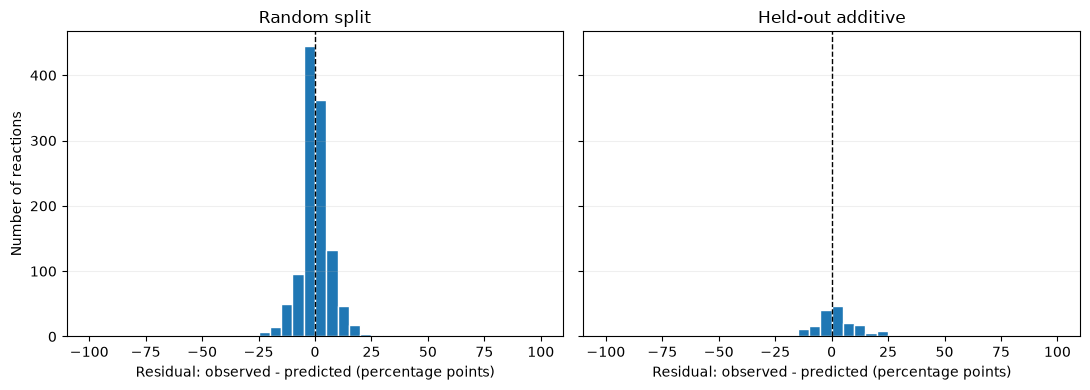

In [3]:
residual_fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), sharex=True, sharey=True
)

for ax, title, table in [
    (axes[0], "Random split", random_predictions),
    (axes[1], "Held-out additive", additive_predictions),
]:
    residuals = table["Output"] - table["predicted_yield"]

    ax.hist(
        residuals,
        bins=np.arange(-100, 105, 5),
        edgecolor="white",
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=title,
        xlabel="Residual: observed - predicted (percentage points)",
    )
    ax.grid(axis="y", alpha=0.2)

    print(f"{title} mean residual: {residuals.mean():.2f} percentage points")
    print(f"{title} largest absolute error: {residuals.abs().max():.2f}")

axes[0].set_ylabel("Number of reactions")

residual_fig.tight_layout()
plt.show()

In [4]:
interval_results = []

for split_name, table in [
    ("Random split", random_predictions),
    ("Held-out additive", additive_predictions),
]:
    analysis = table.copy()
    analysis["residual"] = analysis["Output"] - analysis["predicted_yield"]
    analysis["absolute_error"] = analysis["residual"].abs()

    analysis["yield_interval"] = pd.cut(
        analysis["Output"],
        bins=[-np.inf, 20, 40, 60, 80, np.inf],
        labels=["<20%", "20–<40%", "40–<60%", "60–<80%", ">=80%"],
        right=False,
    )

    summary = analysis.groupby(
        "yield_interval", observed=False
    ).agg(
        records=("Output", "size"),
        mae=("absolute_error", "mean"),
        mean_residual=("residual", "mean"),
    )

    summary.insert(0, "split", split_name)
    interval_results.append(summary.reset_index())

interval_summary = pd.concat(interval_results, ignore_index=True)
display(interval_summary.round(2))

,yield_interval,split,records,mae,mean_residual
0,<20%,Random split,474,3.68,-2.50
1,20–<40%,Random split,245,4.59,-0.99
2,40–<60%,Random split,200,6.07,2.25
3,60–<80%,Random split,181,5.61,3.29
4,>=80%,Random split,87,5.38,4.38
5,<20%,Held-out additive,85,5.49,-4.14
6,20–<40%,Held-out additive,41,7.76,-1.13
7,40–<60%,Held-out additive,22,8.74,7.23
8,60–<80%,Held-out additive,11,14.29,14.29
9,>=80%,Held-out additive,21,17.97,17.97


In [5]:
worst_cases = {}

for split_name, table in [
    ("Random split", random_predictions),
    ("Held-out additive", additive_predictions),
]:
    errors = table.copy()
    errors["residual"] = errors["Output"] - errors["predicted_yield"]
    errors["absolute_error"] = errors["residual"].abs()

    worst = errors.nlargest(5, "absolute_error")
    worst_cases[split_name] = worst

    print(f"\nLargest errors: {split_name}")
    display(
        worst[
            ["Output", "predicted_yield", "residual", "absolute_error",
             "Aryl halide", "Ligand", "Base", "Additive"]
        ].round(2)
    )


Largest errors: Random split


,Output,predicted_yield,residual,absolute_error,Aryl halide,Ligand,Base,Additive
source_row_index,,,,,,,,
2756,0.00,56.77,-56.77,56.77,BrC1=CN=CC=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,CC(C)(C)/N=C(N(C)C)/N(C)C,O=C(OC)C1=NOC(C2=CC=CO2)=C1
1254,64.67,21.32,43.35,43.35,IC1=CN=CC=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C3CCCCC3)...,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,C1(C2=CC=CC=C2)=CON=C1
850,0.00,34.66,-34.66,34.66,BrC1=CC=C(OC)C=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,O=C(OC)C1=NOC(C2=CC=CO2)=C1
2845,47.96,14.66,33.30,33.30,ClC1=CN=CC=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C3CCCCC3)...,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,CC1=CC(C)=NO1
11,18.41,50.67,-32.26,32.26,ClC1=CN=CC=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C(C)(C)C)...,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,C1(C2=CC=CC=C2)=NOC=C1



Largest errors: Held-out additive


,Output,predicted_yield,residual,absolute_error,Aryl halide,Ligand,Base,Additive
source_row_index,,,,,,,,
2293,86.42,42.23,44.19,44.19,BrC1=CN=CC=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,CN1CCCN2C1=NCCC2,C1(C2=CC=CC=C2)=CC=NO1
1322,14.37,55.39,-41.02,41.02,IC1=CN=CC=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,C1(C2=CC=CC=C2)=CC=NO1
1515,15.13,53.16,-38.03,38.03,IC1=CN=CC=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P(C(C)(C)C)...,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,C1(C2=CC=CC=C2)=CC=NO1
747,84.91,48.73,36.18,36.18,BrC1=NC=CC=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,CN1CCCN2C1=NCCC2,C1(C2=CC=CC=C2)=CC=NO1
1447,13.65,48.44,-34.80,34.80,BrC1=CN=CC=C1,CC(C)C(C=C(C(C)C)C=C1C(C)C)=C1C2=C(P([C@@]3(C[...,CN(C)P(N(C)C)(N(C)C)=NP(N(C)C)(N(C)C)=NCC,C1(C2=CC=CC=C2)=CC=NO1


In [6]:
evaluation_dir = Path("reports/evaluation")
evaluation_dir.mkdir(parents=True, exist_ok=True)

evaluation_summary.to_csv(
    evaluation_dir / "metrics.csv", index=False
)
interval_summary.to_csv(
    evaluation_dir / "yield_interval_errors.csv", index=False
)

for split_name, filename in [
    ("Random split", "random"),
    ("Held-out additive", "additive"),
]:
    worst_cases[split_name].to_csv(
        evaluation_dir / f"{filename}_largest_errors.csv"
    )

fig.savefig(
    evaluation_dir / "observed_vs_predicted.png",
    dpi=200,
    bbox_inches="tight",
)
residual_fig.savefig(
    evaluation_dir / "residual_distribution.png",
    dpi=200,
    bbox_inches="tight",
)

print("Saved evaluation tables and figures to reports/evaluation/.")

Saved evaluation tables and figures to reports/evaluation/.


### 模型评估结论

- 选定的 Morgan Random Forest 在随机测试集上的 MAE 为 4.689、
  RMSE 为 7.141 个百分点，R² 为 0.933。
- 在单个添加剂留出测试集上的 MAE 为 8.398、
  RMSE 为 12.130 个百分点，R² 为 0.811。
- 两个场景均有低产率高估、高产率低估的倾向。
- 添加剂留出中，实测产率至少 80% 的 21 条反应，
  平均残差为 +17.97 个百分点，显示明显低估。
- 随机测试和添加剂留出测试的最大绝对误差分别为 56.77 和
  44.19 个百分点。
- 添加剂留出中误差最大的五条反应均使用含吡啶环的芳基卤化物，
  可作为后续模型解释的案例。
- 添加剂留出结果目前只对应一个外部留出添加剂。
- 图表、指标和高误差案例保存在 `reports/evaluation/`。